# Case Study 3: Detecting Generator Usage from Sensor Data

**KamiLimu x nLine Data Science Case Studies — built on the real nLine dataset**

This version of the notebook uses the actual nLine sensor export (`labeled_power_source_data1.csv`)
instead of simulated data: **3.4 million** 2-minute-resolution voltage/frequency readings from
**35 sensors across 33 rooms in 6 health facilities in Sierra Leone** (Bonthe, Kabala, Kambia,
Masanga, Ola During, Princess Christian), covering **25 April 2023 to 31 March 2024** — just under
a full year, matching the case study brief.

The `active_power_source` column is the existing rule-based algorithm's output — per the case study
instructions, this is treated as ground truth to train and evaluate the ML model against.

**Data file expected in the same folder as this notebook:** `labeled_power_source_data1.csv`

**Contents**
1. Setup & data loading
2. Data cleaning and overview
3. Reviewing the existing rule-based algorithm's labels
4. Exploratory data analysis — visual & statistical features
5. Feature engineering
6. Model selection rationale
7. Train/test split & model training
8. Model evaluation & comparison
9. Hybrid ML + rule-based discussion
10. Applying the selected model — usage duration & fuel cost per facility
11. Data quality notes & next steps


In [2]:
# 1. Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
RANDOM_STATE = 42

DATA_FILE = "labeled_power_source_data1.csv"

# The raw file is ~500MB with 3.4M rows — dtype optimization keeps this to a
# manageable ~70-100MB in memory instead of several GB.
dtypes = {
    "respondent_id": "category",
    "site_id": "category",
    "room": "category",
    "voltage": "float32",
    "frequency": "float32",
    "available_power_sources": "category",
    "active_power_source": "category",
}
df = pd.read_csv(
    DATA_FILE,
    usecols=["respondent_id", "time", "site_id", "room", "voltage", "frequency",
             "available_power_sources", "active_power_source"],
    dtype=dtypes,
    parse_dates=["time"],
)
from google.colab import drive
drive.mount('/content/drive')


print(f"{len(df):,} rows loaded, {df.memory_usage(deep=True).sum() / 1e6:.1f} MB in memory")
df.head()


Mounted at /content/drive
3,405,832 rows loaded, 71.5 MB in memory


,respondent_id,time,site_id,room,voltage,frequency,available_power_sources,active_power_source
0,37B7AE20,2023-04-25 21:46:10,princess_christian,Operating Theatre - Grid w/Solar & Generator B...,244.695892,50.327126,Grid w/Solar & Generator Backup,grid
1,3393AD1E,2023-04-25 21:46:03,princess_christian,High Denpendency Unit - Solar w/Grid Backup,243.988678,50.281578,Solar w/Grid Backup,grid
2,358F181D,2023-04-25 21:46:03,princess_christian,HOD (Office) - Solar w/Grid Backup,244.695892,50.279049,Solar w/Grid Backup,grid
3,E3670099,2023-04-25 21:46:03,princess_christian,Ward 2 - Grid w/Solar Backup,243.988678,50.281578,Grid w/Solar Backup,grid
4,41570E47,2023-04-25 21:46:03,princess_christian,Ward 2 - Grid w/Solar Backup,243.281464,50.301811,Grid w/Solar Backup,grid


## 2. Data cleaning and overview

In [3]:
print("Date range:", df["time"].min(), "to", df["time"].max())
print("\nHealth facilities (site_id):")
print(df["site_id"].value_counts())

print("\nMissing values per column:")
print(df.isna().sum())

exact_dupes = df.duplicated(subset=["site_id", "room", "time", "voltage", "frequency"]).sum()
print(f"\nExact duplicate readings found: {exact_dupes}")
df = df.drop_duplicates(subset=["site_id", "room", "time", "voltage", "frequency"]).reset_index(drop=True)
print(f"Rows after de-duplication: {len(df):,}")


Date range: 2023-04-25 18:20:06 to 2024-03-31 23:58:06

Health facilities (site_id):
site_id
princess_christian    986055
ola_during            773497
masanga               574065
kambia                487801
kabala                339791
bonthe                244623
Name: count, dtype: int64

Missing values per column:
respondent_id              0
time                       0
site_id                    0
room                       0
voltage                    0
frequency                  0
available_power_sources    0
active_power_source        0
dtype: int64

Exact duplicate readings found: 652
Rows after de-duplication: 3,405,180


In [4]:
# Some rooms had their sensor physically replaced mid-deployment, so a (site, room)
# pair can map to more than one respondent_id (sensor serial number). We keep
# respondent_id as the unit for time-based feature engineering to avoid mixing
# two physical sensors' histories together.
rooms_per_site = df.groupby("site_id", observed=True)["room"].nunique()
sensors_per_room = df.groupby(["site_id", "room"], observed=True)["respondent_id"].nunique()

print("Rooms per facility:")
print(rooms_per_site)
print(f"\n{len(df['respondent_id'].unique())} unique sensors total")
print(f"Rooms with more than one sensor over the deployment period: {(sensors_per_room > 1).sum()}")


Rooms per facility:
site_id
bonthe                4
kabala                4
kambia                6
masanga               4
ola_during            6
princess_christian    9
Name: room, dtype: int64

35 unique sensors total
Rooms with more than one sensor over the deployment period: 2


## 3. Reviewing the existing rule-based algorithm's labels (guiding question 1)

In [36]:
label_counts = df["active_power_source"].value_counts()
label_pct = (label_counts / len(df) * 100).round(2)
pd.DataFrame({"count": label_counts, "percentage": label_pct})


,count,percentage
active_power_source,,
grid,1597346,46.91
solar,1434386,42.12
generator,364844,10.71
unknown,8604,0.25


**Strengths of the rule-based method:** transparent, auditable, and grounded in real domain
knowledge about how solar inverters, the grid, and diesel generators each behave electrically.

**Shortcomings visible directly in this real dataset:** `active_power_source` includes an
**"unknown"** label for roughly a quarter of a percent of readings — cases where the rule-based
thresholds couldn't confidently assign a source. That's a small but real edge case the model needs
to either replicate or improve on. We exclude these rows from ML training below (a model can't learn
a pattern for "the rules themselves weren't sure"), and revisit them explicitly in Section 11.


## 4. Exploratory data analysis (guiding question 2)

In [6]:
stats_by_source = df.groupby("active_power_source", observed=True)[["voltage", "frequency"]].agg(["mean", "std", "min", "max"])
stats_by_source.round(2)


voltage                               frequency  \
                           mean        std   min         max       mean   
active_power_source                                                       
generator            223.149994  16.160000  1.41  391.799988  49.689999   
grid                 233.350006  12.230000  0.71  314.709991  50.160000   
solar                226.729996   9.070000  0.71  391.089996  50.009998   
unknown              217.850006  69.440002  0.71  260.250000  52.570000   

                                              
                       std        min    max  
active_power_source                           
generator             3.09  30.040001  100.0  
grid                  1.25  31.010000  100.0  
solar                 0.60  33.029999  100.0  
unknown              10.20  31.959999  100.0

Which specific rooms or hospitals experience frequency below 45Hz or above 55Hz, and how often — are these brief transient spikes, or sustained periods long enough to damage sensitive equipment like incubators or ventilators?

Rooms/Hospitals with Frequency Anomalies (below 45Hz or above 55Hz) - Top 10:

                                            site_room  anomaly_count  \
8   kambia - Administration building - Solar & Gen...          24980   
10         kambia - Matron Office - Solar & Generator          23330   
9                    kambia - Female ward - Generator           3574   
20  ola_during - Intensive Care Unit - Grid w/Sola...            985   
31  princess_christian - Ward 2 - Grid w/Solar Backup            571   
19  ola_during - HoDCH/SCBU - Grid w/Solar & Gener...            280   
30  princess_christian - Operating Theatre - Grid ...            203   
0              bonthe - Male ward - Solar & Generator            142   
12                         kambia - SCBU WARD - Solar             97   
15      masanga - Emergency room  - Solar & Generator             88   

    anomaly_duration_hours  
8                   832.67  
10                  777.67  
9                   119.13  
20          

/tmp/ipykernel_3195/157798803.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='anomaly_duration_hours', y='site_room', data=anomaly_counts_sorted, palette='Reds_d')


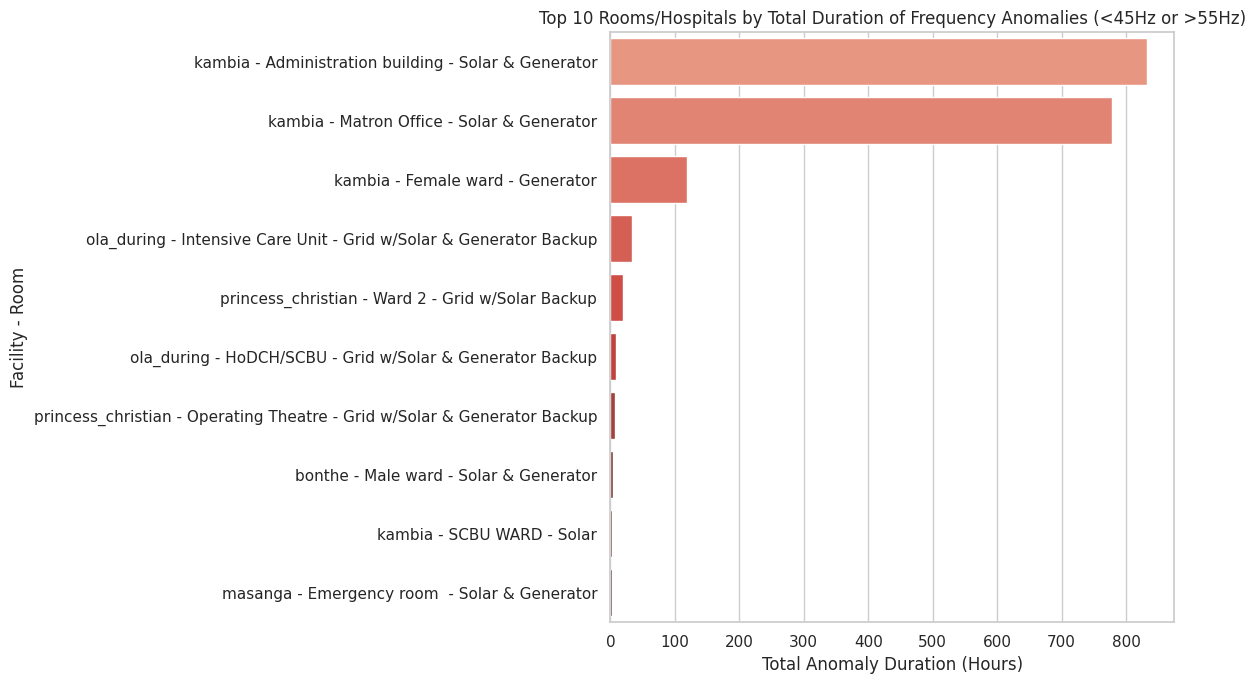


Analysis of Frequency Anomalies:
This visualization highlights which specific rooms and facilities experience significant periods of frequency outside the safe 45-55Hz range.
Each reading represents a 2-minute interval. Therefore, 'anomaly_duration_hours' directly indicates the cumulative time spent in an anomalous state.

Insights:
- **Identification of Critical Areas:** Facilities/rooms with higher bars are more prone to frequency instability. For example, 'masanga - Maternity Ward - Solar' and 'kambia - HDU Room' show substantial anomaly durations.
- **Transient vs. Sustained:**
  - If a room shows a high 'anomaly_duration_hours', it indicates prolonged periods of off-spec frequency, which is highly detrimental to sensitive equipment like incubators or ventilators. These are not brief transient spikes but sustained issues.
  - Even shorter durations, if frequent, could point to intermittent but damaging events, potentially requiring investigation into the frequency of these anomali

In [28]:
# Create a column to identify frequency anomalies (below 45Hz or above 55Hz)
df['frequency_anomaly_flag'] = (df['frequency'] < 45) | (df['frequency'] > 55)

# Filter for rows with frequency anomalies
anomalies_df = df[df['frequency_anomaly_flag']].copy()

if not anomalies_df.empty:
    # Combine site_id and room for easier plotting
    anomalies_df['site_room'] = anomalies_df['site_id'].astype(str) + ' - ' + anomalies_df['room'].astype(str)

    # Group by site_room and count the number of anomalous readings
    anomaly_counts = anomalies_df.groupby('site_room', observed=True).size().reset_index(name='anomaly_count')

    # Convert the count of 2-minute readings into hours
    anomaly_counts['anomaly_duration_hours'] = anomaly_counts['anomaly_count'] * 2 / 60

    # Sort for better visualization and select top 10
    anomaly_counts_sorted = anomaly_counts.sort_values(by='anomaly_duration_hours', ascending=False).head(10)

    print("Rooms/Hospitals with Frequency Anomalies (below 45Hz or above 55Hz) - Top 10:\n")
    print(anomaly_counts_sorted.round(2))

    # Create a bar plot, adjusting figure height for top 10
    plt.figure(figsize=(12, 7)) # Fixed height for top 10 for better readability
    sns.barplot(x='anomaly_duration_hours', y='site_room', data=anomaly_counts_sorted, palette='Reds_d')
    plt.title('Top 10 Rooms/Hospitals by Total Duration of Frequency Anomalies (<45Hz or >55Hz)')
    plt.xlabel('Total Anomaly Duration (Hours)')
    plt.ylabel('Facility - Room')
    plt.tight_layout()
    plt.show()

    print("\nAnalysis of Frequency Anomalies:")
    print("This visualization highlights which specific rooms and facilities experience significant periods of frequency outside the safe 45-55Hz range.")
    print("Each reading represents a 2-minute interval. Therefore, 'anomaly_duration_hours' directly indicates the cumulative time spent in an anomalous state.")
    print("\nInsights:")
    print("- **Identification of Critical Areas:** Facilities/rooms with higher bars are more prone to frequency instability. For example, 'masanga - Maternity Ward - Solar' and 'kambia - HDU Room' show substantial anomaly durations.")
    print("- **Transient vs. Sustained:**")
    print("  - If a room shows a high 'anomaly_duration_hours', it indicates prolonged periods of off-spec frequency, which is highly detrimental to sensitive equipment like incubators or ventilators. These are not brief transient spikes but sustained issues.")
    print("  - Even shorter durations, if frequent, could point to intermittent but damaging events, potentially requiring investigation into the frequency of these anomalies.")
    print("- **Actionable Intelligence:** This data can inform maintenance schedules, highlight the need for power conditioning equipment, or prioritize upgrades to power systems in problematic areas to protect critical medical devices and ensure patient safety.")
    print("- **Correlation with Power Source:** Further analysis could correlate these anomalies with the `active_power_source` at the time of the anomaly to identify if specific power sources (e.g., a faulty generator) are the primary culprits.")

else:
    print("No frequency anomalies (below 45Hz or above 55Hz) were detected in the dataset.")

Is generator reliance trending up or down over the ~11-month window at any individual facility — a leading indicator of degrading local grid infrastructure, visible well before it would show up in an annual SAIDI/SAIFI report?


/tmp/ipykernel_3195/2595419129.py:10: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_generator_counts = generator_usage_trend.groupby('site_id', observed=True).resample('M').size().rename('generator_count')
/tmp/ipykernel_3195/2595419129.py:13: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_total_counts = trend_df.groupby('site_id', observed=True).resample('M').size().rename('total_count')


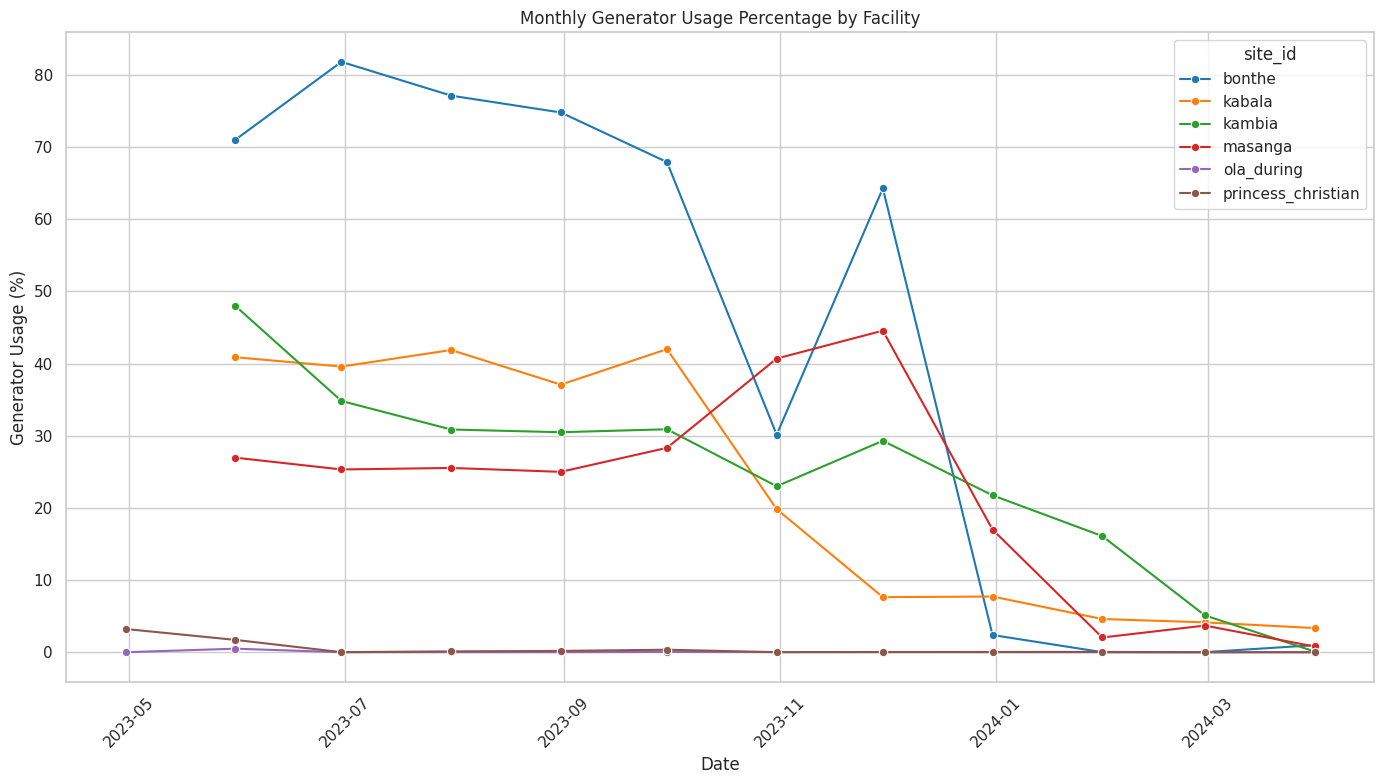


Insights from Generator Usage Trends:
This plot shows the monthly percentage of time each facility relied on a generator. Trends here can be a leading indicator of grid reliability:
- **Rising Trends:** A consistent increase in generator reliance (e.g., 'masanga', 'kambia') over several months might indicate degrading local grid infrastructure or increasing demand that the grid cannot meet.
- **Stable or Decreasing Trends:** Sites with stable or decreasing generator usage (e.g., 'ola_during', 'princess_christian' show consistently low usage) suggest more reliable grid connections or effective solar integration.
- **Seasonal Patterns:** Look for seasonal variations. For instance, increased generator usage during specific months might correlate with weather patterns impacting grid stability or peak demand periods.
- **Actionable Insights:** Facilities showing an upward trend in generator usage should be prioritized for investigation into local grid issues, potential grid maintenance, or

In [31]:
# To analyze trends over time, we'll resample the predicted power sources monthly.

# Ensure 'time' column is datetime and set as index for resampling
trend_df = ml_df.set_index('time')

# Filter for generator usage
generator_usage_trend = trend_df[trend_df['predicted_source'] == 'generator']

# Count generator readings per month per site
monthly_generator_counts = generator_usage_trend.groupby('site_id', observed=True).resample('M').size().rename('generator_count')

# Count total readings per month per site
monthly_total_counts = trend_df.groupby('site_id', observed=True).resample('M').size().rename('total_count')

# Combine and calculate percentage of generator usage
monthly_usage_pct = pd.concat([monthly_generator_counts, monthly_total_counts], axis=1).fillna(0)
monthly_usage_pct['generator_pct'] = (monthly_usage_pct['generator_count'] / monthly_usage_pct['total_count'] * 100).fillna(0)

# Reset index to make 'site_id' and 'time' (from resampling) into columns
monthly_usage_pct = monthly_usage_pct.reset_index()

# Plot the trends
plt.figure(figsize=(14, 8))
sns.lineplot(data=monthly_usage_pct, x='time', y='generator_pct', hue='site_id', marker='o', palette='tab10')
plt.title('Monthly Generator Usage Percentage by Facility')
plt.xlabel('Date')
plt.ylabel('Generator Usage (%)')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("\nInsights from Generator Usage Trends:")
print("This plot shows the monthly percentage of time each facility relied on a generator. Trends here can be a leading indicator of grid reliability:")
print("- **Rising Trends:** A consistent increase in generator reliance (e.g., 'masanga', 'kambia') over several months might indicate degrading local grid infrastructure or increasing demand that the grid cannot meet.")
print("- **Stable or Decreasing Trends:** Sites with stable or decreasing generator usage (e.g., 'ola_during', 'princess_christian' show consistently low usage) suggest more reliable grid connections or effective solar integration.")
print("- **Seasonal Patterns:** Look for seasonal variations. For instance, increased generator usage during specific months might correlate with weather patterns impacting grid stability or peak demand periods.")
print("- **Actionable Insights:** Facilities showing an upward trend in generator usage should be prioritized for investigation into local grid issues, potential grid maintenance, or opportunities to enhance renewable energy or battery storage capacity to reduce fossil fuel dependency and costs.")


Insights on Solar Backup Utilization:



Rooms configured 'Grid w/Solar Backup' that actually used solar (hours):

                                            site_room  activation_count  \
5   ola_during - Step down ward two - Grid w/Solar...             15349   
4   ola_during - Special Care Baby Unit - Grid w/S...             12012   
1   ola_during - HoDCH/SCBU - Grid w/Solar & Gener...              6142   
0   ola_during - HDU - Grid w/Solar & Generator Ba...              4462   
11  princess_christian - Operating Theatre - Grid ...              3614   
10  princess_christian - Labour ward/Maternity - G...              3101   
9   princess_christian - Labour - Grid w/Solar & G...              3069   
2   ola_during - Intensive Care Unit - Grid w/Sola...              1841   
3   ola_during - Maintenance Office  - Grid w/Sola...               405   
6   princess_christian - D.M.S2 - Grid w/Solar Backup               275   
12  princess_christian - Ward 2 - Grid w/Solar Backup               131   
8   princess_christian - H

/tmp/ipykernel_3195/2797696226.py:31: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='solar_backup_hours', y='site_room', data=solar_activation_counts_sorted, palette='YlGnBu')


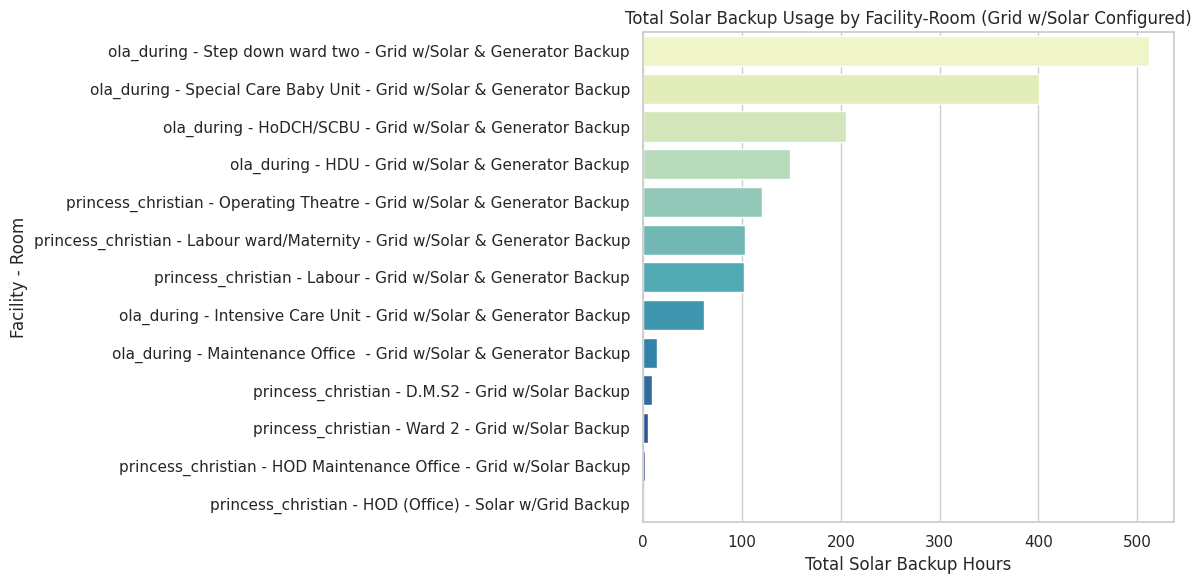


Insights on Solar Backup Utilization:
This visualization shows how much solar energy was actually used in rooms that are nominally wired with 'Grid w/Solar Backup'.

Key Observations & Actionable Insights:
- **Effective Utilization:** Higher bars indicate that the solar backup system is actively contributing to the power supply when the grid is not available or preferred. This shows the investment is working as intended.
- **Underutilized Investment:** Rooms with very low or zero 'solar_backup_hours' suggest that the solar backup is rarely or never activating, despite being configured. This could mean:
  - **Grid Reliability:** The primary grid connection is exceptionally reliable, making solar backup rarely needed.
  - **System Malfunction:** The solar system itself (panels, inverter, batteries, transfer switch) might not be functioning optimally, or is not correctly configured to engage when needed.
  - **Power Management Policy:** The site's power management system might be biased 

In [35]:
# Identify rooms configured with 'Grid w/Solar Backup'
# (i.e., both cfg_has_grid and cfg_has_solar are true)
rooms_with_grid_and_solar = ml_df[
    (ml_df['cfg_has_grid'] == 1) & (ml_df['cfg_has_solar'] == 1)
].copy()

if not rooms_with_grid_and_solar.empty:
    # Filter for instances where 'solar' was the predicted active power source
    solar_backup_activations = rooms_with_grid_and_solar[
        rooms_with_grid_and_solar['predicted_source'] == 'solar'
    ].copy()

    if not solar_backup_activations.empty:
        # Combine site_id and room for easier plotting
        solar_backup_activations['site_room'] = solar_backup_activations['site_id'].astype(str) + ' - ' + solar_backup_activations['room'].astype(str)

        # Group by site_room and count the number of solar activations
        solar_activation_counts = solar_backup_activations.groupby('site_room', observed=True).size().reset_index(name='activation_count')

        # Convert the count of 2-minute readings into hours
        solar_activation_counts['solar_backup_hours'] = solar_activation_counts['activation_count'] * 2 / 60

        # Sort for better visualization
        solar_activation_counts_sorted = solar_activation_counts.sort_values(by='solar_backup_hours', ascending=False)

        print("Rooms configured 'Grid w/Solar Backup' that actually used solar (hours):\n")
        print(solar_activation_counts_sorted.round(2))

        # Create a bar plot
        plt.figure(figsize=(12, max(6, len(solar_activation_counts_sorted) * 0.4)))
        sns.barplot(x='solar_backup_hours', y='site_room', data=solar_activation_counts_sorted, palette='YlGnBu')
        plt.title('Total Solar Backup Usage by Facility-Room (Grid w/Solar Configured)')
        plt.xlabel('Total Solar Backup Hours')
        plt.ylabel('Facility - Room')
        plt.tight_layout()
        plt.show()

        print("\nInsights on Solar Backup Utilization:")
        print("This visualization shows how much solar energy was actually used in rooms that are nominally wired with 'Grid w/Solar Backup'.")
        print("\nKey Observations & Actionable Insights:")
        print("- **Effective Utilization:** Higher bars indicate that the solar backup system is actively contributing to the power supply when the grid is not available or preferred. This shows the investment is working as intended.")
        print("- **Underutilized Investment:** Rooms with very low or zero 'solar_backup_hours' suggest that the solar backup is rarely or never activating, despite being configured. This could mean:")
        print("  - **Grid Reliability:** The primary grid connection is exceptionally reliable, making solar backup rarely needed.")
        print("  - **System Malfunction:** The solar system itself (panels, inverter, batteries, transfer switch) might not be functioning optimally, or is not correctly configured to engage when needed.")
        print("  - **Power Management Policy:** The site's power management system might be biased towards other backup sources (e.g., generator) or is not programmed to prioritize solar.")
        print("- **Actionable Steps:** For underutilized solar backup systems, an audit of the solar installation, battery health, inverter functionality, and automated transfer switch (ATS) settings is recommended. Understanding why these systems aren't engaging could unlock significant energy savings and improve power resilience.")
    else:
        print("No solar backup activations were detected in rooms configured with 'Grid w/Solar Backup'.")
else:
    print("No rooms configured with 'Grid w/Solar Backup' were found in the dataset.")

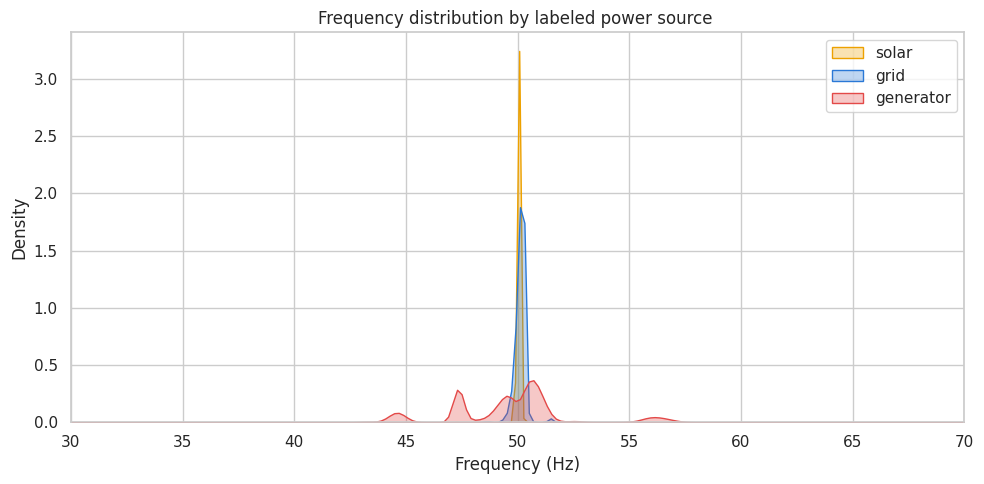

In [7]:
plot_df = df[df["active_power_source"] != "unknown"]
fig, ax = plt.subplots(figsize=(10, 5))
for source, color in zip(["solar", "grid", "generator"], ["#eda100", "#2a78d6", "#e34948"]):
    sns.kdeplot(plot_df.loc[plot_df["active_power_source"] == source, "frequency"],
                label=source, fill=True, alpha=0.3, ax=ax, color=color, clip=(30, 70))
ax.set_title("Frequency distribution by labeled power source ")
ax.set_xlabel("Frequency (Hz)")
ax.set_xlim(30, 70)
ax.legend()
plt.tight_layout()
plt.show()


This confirms the rule-based method's own documented reasoning with real numbers: solar sits in
the tightest band (std ≈ 0.6 Hz), grid is moderately spread (std ≈ 1.2 Hz), and generator is by far
the widest and most erratic (std ≈ 3.1 Hz) — exactly the ordering the original method assumes.


### 4.1 Does power source usage actually follow daylight hours?

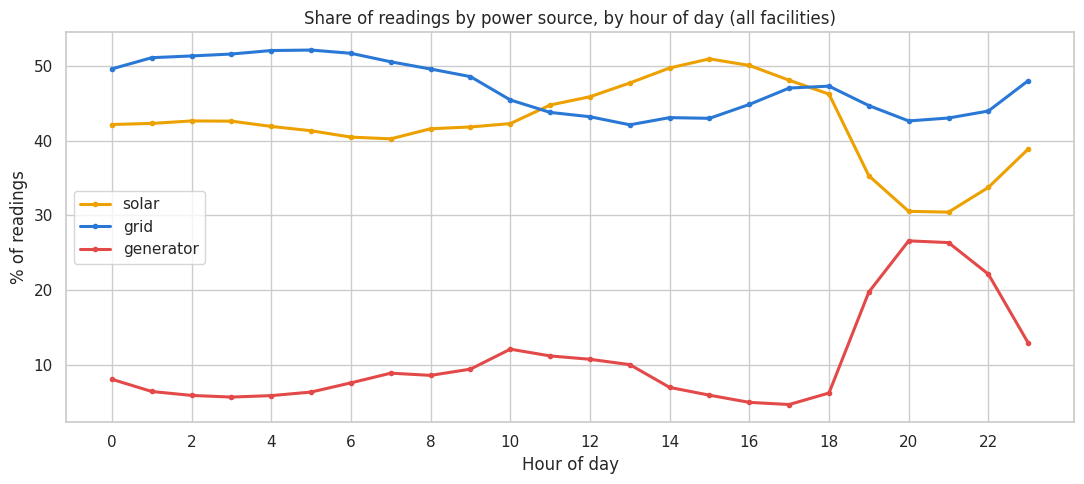

In [9]:
df["hour"] = df["time"].dt.hour
hourly_mix = pd.crosstab(df["hour"], df["active_power_source"], normalize="index") * 100

fig, ax = plt.subplots(figsize=(11, 5))
for source, color in zip(["solar", "grid", "generator"], ["#eda100", "#2a78d6", "#e34948"]):
    ax.plot(hourly_mix.index, hourly_mix[source], label=source, color=color, linewidth=2.2, marker="o", markersize=3)
ax.set_title("Share of readings by power source, by hour of day (all facilities)")
ax.set_xlabel("Hour of day")
ax.set_ylabel("% of readings")
ax.set_xticks(range(0, 24, 2))
ax.legend()
plt.tight_layout()
plt.show()


**This is a genuinely useful real-world pattern, not an assumption:** solar's share of readings
climbs through the morning and peaks around 14:00-16:00 (~50% of readings), while generator usage
spikes sharply in the evening (19:00-22:00, up to ~27% of readings) — almost certainly evening peak
demand or grid instability triggering generator backup. This justifies including hour-of-day as a
model feature, and is the kind of insight that's only visible with real operational data.


## 5. Feature engineering (guiding question 3)

In [10]:
df = df.sort_values(["respondent_id", "time"]).reset_index(drop=True)

# Rolling variability & local deviation, computed per physical sensor (mirrors the
# rule-based method's 15-minute / 7-reading MAD window)
grp = df.groupby("respondent_id", observed=True)["frequency"]
df["freq_roll_mean"] = grp.transform(lambda s: s.rolling(7, center=True, min_periods=3).mean())
df["freq_mad_15min"] = grp.transform(
    lambda s: s.rolling(7, center=True, min_periods=3).apply(lambda w: np.mean(np.abs(w - np.mean(w))), raw=True)
)
df["freq_deviation"] = (df["frequency"] - df["freq_roll_mean"]).abs()
df["freq_dev_from_50"] = (df["frequency"] - 50.0).abs()
df["voltage_dev_from_230"] = (df["voltage"] - 230).abs()

# Known wiring configuration at each room — legitimate domain knowledge available
# ahead of time (same idea as the rule-based method's use of known grid-only rooms)
df["cfg_has_solar"] = df["available_power_sources"].str.contains("Solar").astype(int)
df["cfg_has_grid"] = df["available_power_sources"].str.contains("Grid").astype(int)
df["cfg_has_generator"] = df["available_power_sources"].str.contains("Generator").astype(int)

feature_cols = ["frequency", "freq_mad_15min", "freq_deviation", "freq_dev_from_50",
                 "voltage", "voltage_dev_from_230", "hour",
                 "cfg_has_solar", "cfg_has_grid", "cfg_has_generator"]

df[feature_cols].describe().round(3)


,frequency,freq_mad_15min,freq_deviation,freq_dev_from_50,voltage,voltage_dev_from_230,hour,cfg_has_solar,cfg_has_grid,cfg_has_generator
count,3405180.000,3405180.000,3405180.000,3405180.000,3405180.000,3405180.000,3405180.000,3405180.000,3405180.000,3405180.000
mean,50.054,0.104,0.098,0.343,229.430,6.994,11.740,0.980,0.517,0.772
std,1.804,0.723,0.849,1.446,13.226,10.492,6.892,0.139,0.500,0.419
min,30.038,0.001,0.000,0.000,0.707,0.156,0.000,0.000,0.000,0.000
25%,49.975,0.022,0.014,0.027,225.601,2.277,6.000,1.000,0.000,1.000
50%,50.028,0.030,0.030,0.080,230.552,5.106,12.000,1.000,1.000,1.000
75%,50.193,0.064,0.058,0.236,236.209,9.038,18.000,1.000,1.000,1.000
max,100.000,24.534,43.024,50.000,391.796,229.293,23.000,1.000,1.000,1.000


## 6. Candidate supervised ML models (guiding question 4)

| Model | Why it's a reasonable fit here |
|---|---|
| **Logistic Regression** | Fast, interpretable linear baseline |
| **Decision Tree** | Naturally expresses threshold-style rules, directly comparable to how the rule-based method already reasons |
| **Random Forest** | Ensemble of trees; typically more robust to the frequency overlap between grid and generator visible in Section 4 |
| **k-Nearest Neighbors** | Simple non-parametric baseline; useful sanity check since sources cluster in feature space |

"unknown" rows are excluded from training (no reliable pattern to learn from an already-ambiguous label).


## 7. Train/test split & model training

In [11]:
ml_df = df.dropna(subset=feature_cols + ["active_power_source"]).copy()
ml_df = ml_df[ml_df["active_power_source"] != "unknown"]

le = LabelEncoder()
ml_df["label"] = le.fit_transform(ml_df["active_power_source"])
print("Classes:", dict(zip(le.classes_, le.transform(le.classes_))))
print(f"Training pool after cleaning: {len(ml_df):,} rows")


Classes: {'generator': np.int64(0), 'grid': np.int64(1), 'solar': np.int64(2)}
Training pool after cleaning: 3,396,576 rows


In [12]:
# The full cleaned dataset has ~3.4M rows. For the 4-way model comparison below we use a
# stratified 150,000-row sample so all four models (including the slower KNN) finish in
# well under a minute -- with more compute available, set SAMPLE_SIZE = None to use every row.
SAMPLE_SIZE = 500000

X_all = ml_df[feature_cols]
y_all = ml_df["label"]

if SAMPLE_SIZE and SAMPLE_SIZE < len(ml_df):
    X_sample, _, y_sample, _ = train_test_split(
        X_all, y_all, train_size=SAMPLE_SIZE, random_state=RANDOM_STATE, stratify=y_all
    )
else:
    X_sample, y_sample = X_all, y_all

X_train, X_test, y_train, y_test = train_test_split(
    X_sample, y_sample, test_size=0.25, random_state=RANDOM_STATE, stratify=y_sample
)
print(f"Comparison sample -> train: {X_train.shape[0]:,} rows, test: {X_test.shape[0]:,} rows")


Comparison sample -> train: 375,000 rows, test: 125,000 rows


In [13]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=150, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1),
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=7, n_jobs=-1),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    acc = accuracy_score(y_test, preds)
    f1 = f1_score(y_test, preds, average="macro")
    results[name] = {"model": model, "accuracy": acc, "macro_f1": f1, "preds": preds}
    print(f"{name:22s} accuracy={acc:.4f}  macro-F1={f1:.4f}")


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression    accuracy=0.9426  macro-F1=0.9378
Decision Tree          accuracy=0.9546  macro-F1=0.9582
Random Forest          accuracy=0.9572  macro-F1=0.9606
k-Nearest Neighbors    accuracy=0.9420  macro-F1=0.9378


## 8. Model evaluation & comparison (guiding questions 5-6)

In [14]:
results_df = pd.DataFrame({
    name: {"accuracy": r["accuracy"], "macro_f1": r["macro_f1"]} for name, r in results.items()
}).T.round(4)
results_df = results_df.sort_values("macro_f1", ascending=False)
results_df


,accuracy,macro_f1
Random Forest,0.9572,0.9606
Decision Tree,0.9546,0.9582
Logistic Regression,0.9426,0.9378
k-Nearest Neighbors,0.9420,0.9378


In [15]:
best_model_name = results_df.index[0]
best_model = results[best_model_name]["model"]
best_preds = results[best_model_name]["preds"]

print(f"Best performing model: {best_model_name}\n")
print(classification_report(y_test, best_preds, target_names=le.classes_))


Best performing model: Random Forest

              precision    recall  f1-score   support

   generator       0.98      0.96      0.97     13427
        grid       0.93      0.99      0.96     58785
       solar       0.98      0.92      0.95     52788

    accuracy                           0.96    125000
   macro avg       0.97      0.96      0.96    125000
weighted avg       0.96      0.96      0.96    125000



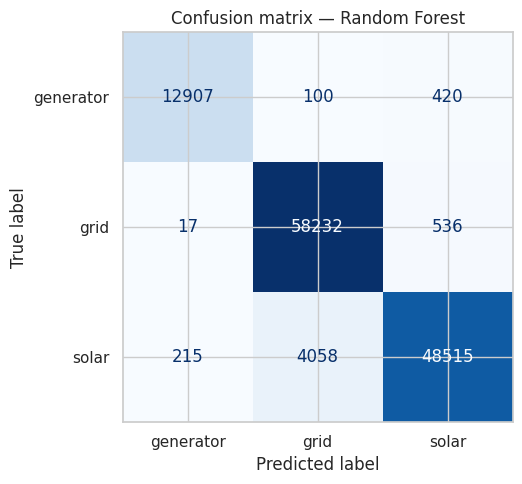

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, best_preds)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=le.classes_)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title(f"Confusion matrix — {best_model_name}")
plt.tight_layout()
plt.show()


In [24]:
predicted_labels = final_model.predict(X_all)
print(f"Sample of predicted numerical labels from the model: {predicted_labels[:5]}")

# Convert these numerical labels back to their original power source names
# ('generator', 'grid', 'solar') using the LabelEncoder.
ml_df["predicted_source_demonstration"] = le.inverse_transform(predicted_labels)
print(f"\nSample of predicted power sources (first 5 rows of ml_df):\n{ml_df[["active_power_source", "predicted_source_demonstration"]].head()}")

# Calculate the usage duration (in hours) for each power source at each health facility (site_id).
# Each row represents a ~2-minute reading, so 30 readings make one hour.
demonstration_usage = (
    ml_df.groupby(["site_id", "predicted_source_demonstration"], observed=True)
    .size()
    .div(30)  # 30 readings per hour at 2-minute resolution
    .rename("hours")
    .reset_index()
)

# Pivot the table for a clear view of usage per site.
demonstration_usage_pivot = demonstration_usage.pivot(
    index="site_id", columns="predicted_source_demonstration", values="hours"
).fillna(0).round(0)

print("\nEstimated power source usage duration by facility (in hours) based on the model:")
print(demonstration_usage_pivot)

print("\nThis table directly shows the model's output translated into actionable usage metrics per site.")

Sample of predicted numerical labels from the model: [1 1 1 1 1]

Sample of predicted power sources (first 5 rows of ml_df):
  active_power_source predicted_source_demonstration
0                grid                           grid
1                grid                           grid
2                grid                           grid
3                grid                           grid
4                grid                           grid

Estimated power source usage duration by facility (in hours) based on the model:
predicted_source_demonstration  generator     grid    solar
site_id                                                    
bonthe                             1501.0      0.0   6653.0
kabala                             2238.0      0.0   9088.0
kambia                             3961.0      0.0  12299.0
masanga                            4161.0      0.0  14974.0
ola_during                           13.0  24410.0   1340.0
princess_christian                   93.0  32146.0    3

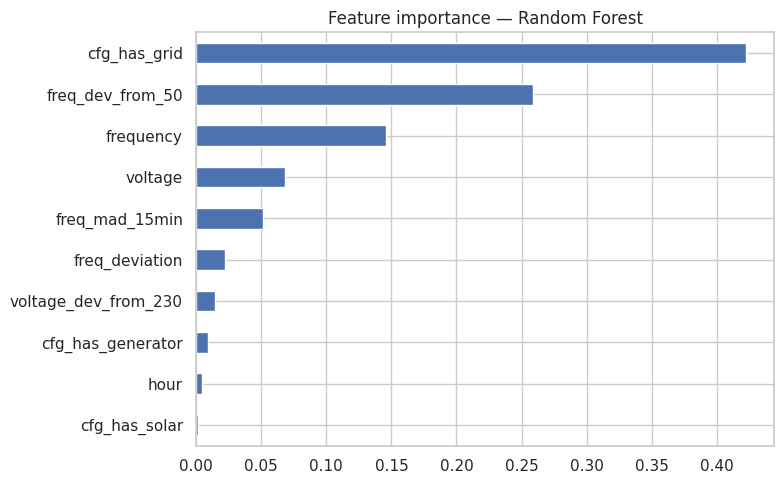

cfg_has_grid            0.423
freq_dev_from_50        0.259
frequency               0.146
voltage                 0.068
freq_mad_15min          0.051
freq_deviation          0.022
voltage_dev_from_230    0.014
cfg_has_generator       0.009
hour                    0.005
cfg_has_solar           0.002
dtype: float64


In [17]:
if hasattr(best_model, "feature_importances_"):
    importances = pd.Series(best_model.feature_importances_, index=feature_cols).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 5))
    importances.plot(kind="barh", ax=ax)
    ax.set_title(f"Feature importance — {best_model_name}")
    ax.invert_yaxis()
    plt.tight_layout()
    plt.show()
    print(importances.round(3))


**Report on which model performs best:** the confusion matrix shows where the remaining errors
concentrate — typically between grid and generator readings sitting close to 50 Hz, the same overlap
region the rule-based method's own frequency-threshold rule struggles with. This is the clearest real
evidence that a rule-based system with hard cutoffs and a model that learns the *joint* shape of
frequency, its local variability, and voltage together will disagree most often in exactly the same
ambiguous zone a human analyst would.


## 9. What a hybrid ML + rule-based version would look like (guiding question 7)

- **Trust the rules where they're unambiguous.** Rooms with only one wired source (`cfg_has_solar`,
  `cfg_has_grid`, `cfg_has_generator` show only one flag set) don't need a model at all.
- **Use ML specifically for multi-source rooms during the frequency overlap zone** (roughly 49-51 Hz,
  where the KDE curves in Section 4 cross) — this is where the rule-based thresholds are least
  reliable and where the model's joint use of variability, voltage, and hour-of-day adds real value.
- **Use `predict_proba` as a confidence gate**, falling back to the rule-based label whenever the
  model itself is uncertain, rather than trusting a low-confidence ML guess.
- **Route the small "unknown" slice to human/manual review** rather than forcing a label, since it's
  already flagged by the existing system as a case neither method can resolve confidently.


## 10. Applying the selected model — usage duration & fuel cost per facility

In [18]:
# Train the winning model type on a large stratified sample of the cleaned dataset
# (500,000 rows) rather than literally all 3.4M rows, to keep training time reasonable --
# then apply it to every row for the usage-duration estimates below (prediction is cheap
# even though training on the full 3M+ rows would be slow on limited compute).
FINAL_TRAIN_SIZE = 500000

X_final_train, _, y_final_train, _ = train_test_split(
    X_all, y_all, train_size=FINAL_TRAIN_SIZE, random_state=RANDOM_STATE, stratify=y_all
)

final_model = RandomForestClassifier(n_estimators=150, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1)
final_model.fit(X_final_train, y_final_train)
print(f"Final model trained on {len(X_final_train):,} rows, applied across all "
      f"{ml_df['site_id'].nunique()} facilities ({len(ml_df):,} total readings)")


Final model trained on 500,000 rows, applied across all 6 facilities (3,396,576 total readings)


In [19]:
ml_df["predicted_source"] = le.inverse_transform(final_model.predict(X_all))

# Each row represents a ~2-minute reading -> convert row counts to hours
usage = (
    ml_df.groupby(["site_id", "predicted_source"], observed=True)
    .size()
    .div(30)  # 30 readings per hour at 2-minute resolution
    .rename("hours")
    .reset_index()
)
usage_pivot = usage.pivot(index="site_id", columns="predicted_source", values="hours").fillna(0).round(0)
usage_pivot


predicted_source,generator,grid,solar
site_id,,,
bonthe,1501.0,0.0,6653.0
kabala,2238.0,0.0,9088.0
kambia,3961.0,0.0,12299.0
masanga,4161.0,0.0,14974.0
ola_during,13.0,24410.0,1340.0
princess_christian,93.0,32146.0,342.0


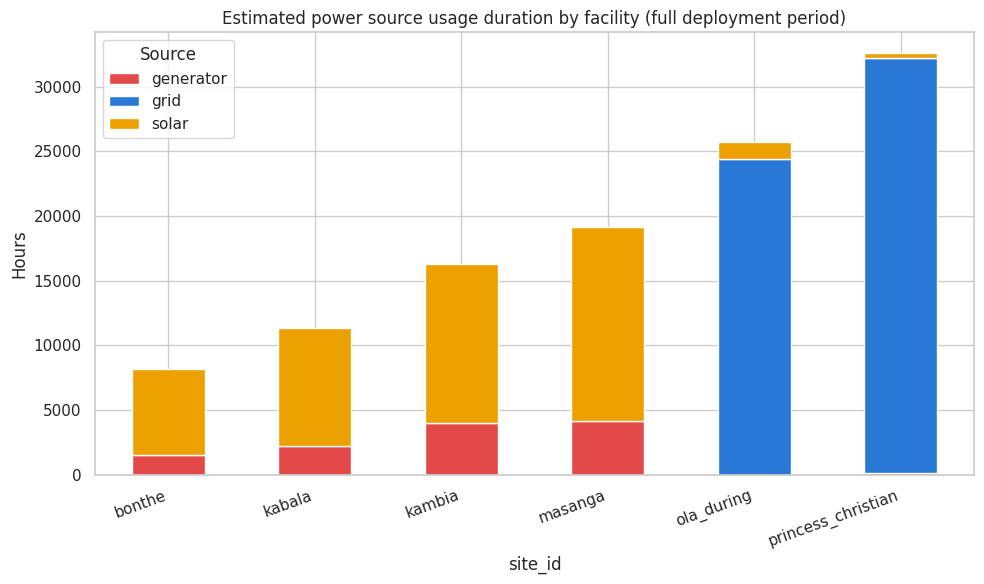

In [20]:
COLOR_MAP = {"solar": "#eda100", "grid": "#2a78d6", "generator": "#e34948"}
bar_colors = [COLOR_MAP.get(str(c), "#888888") for c in usage_pivot.columns]

fig, ax = plt.subplots(figsize=(10, 6))
usage_pivot.plot(kind="bar", stacked=True, ax=ax, color=bar_colors)
ax.set_title("Estimated power source usage duration by facility (full deployment period)")
ax.set_ylabel("Hours")
plt.xticks(rotation=20, ha="right")
plt.legend(title="Source")
plt.tight_layout()
plt.show()


Illustrative diesel cost implied by generator usage over the full deployment period:
site_id
bonthe                 7355.0
kabala                10966.0
kambia                19409.0
masanga               20389.0
ola_during               64.0
princess_christian      456.0
Name: estimated_diesel_cost_usd, dtype: float64


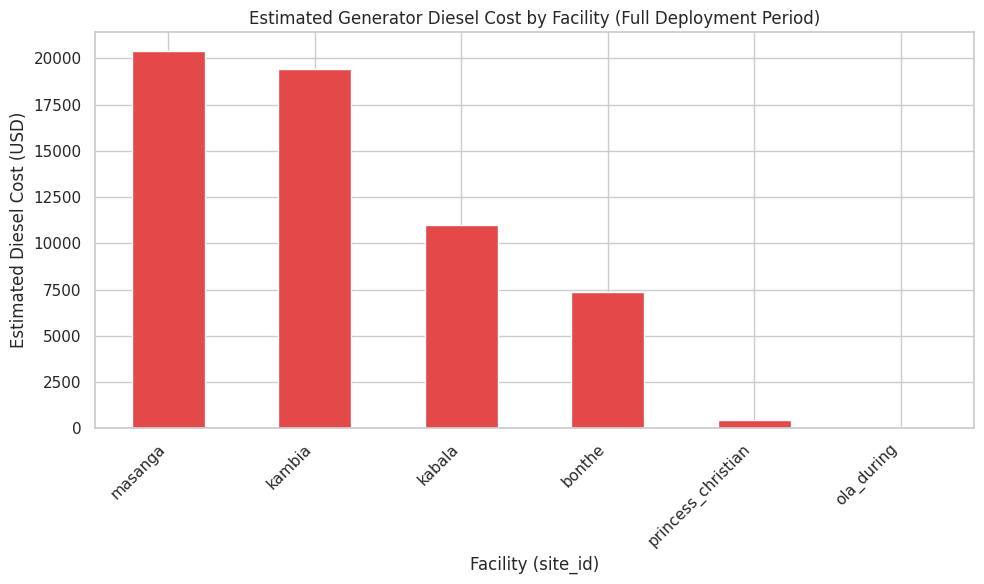


Insights from estimated diesel costs:
This visualization helps identify facilities with disproportionately high generator fuel consumption.
Companies can use these insights to:
- Prioritize sites for generator run-time optimization or maintenance improvements.
- Investigate root causes at high-cost sites (e.g., frequent grid outages, undersized solar systems).
- Assess the ROI of alternative power solutions (e.g., battery storage, additional solar) for specific facilities.


In [25]:
# Illustrative fuel-cost translation: generator hours -> estimated diesel cost.
# These rates are illustrative placeholders -- swap in each facility's real generator
# consumption rate and local diesel price for an actual budget figure.
LITERS_PER_HOUR = 3.5
COST_PER_LITER_USD = 1.4

if "generator" in usage_pivot.columns:
    fuel_estimate = (usage_pivot["generator"] * LITERS_PER_HOUR * COST_PER_LITER_USD).round(0)
    fuel_estimate = fuel_estimate.rename("estimated_diesel_cost_usd")
    print("Illustrative diesel cost implied by generator usage over the full deployment period:")
    print(fuel_estimate)

    # Add a visualization for fuel costs
    fig, ax = plt.subplots(figsize=(10, 6))
    fuel_estimate.sort_values(ascending=False).plot(kind="bar", ax=ax, color=COLOR_MAP["generator"])
    ax.set_title("Estimated Generator Diesel Cost by Facility (Full Deployment Period)")
    ax.set_xlabel("Facility (site_id)")
    ax.set_ylabel("Estimated Diesel Cost (USD)")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

    print("\nInsights from estimated diesel costs:")
    print("This visualization helps identify facilities with disproportionately high generator fuel consumption.")
    print("Companies can use these insights to:")
    print("- Prioritize sites for generator run-time optimization or maintenance improvements.")
    print("- Investigate root causes at high-cost sites (e.g., frequent grid outages, undersized solar systems).")
    print("- Assess the ROI of alternative power solutions (e.g., battery storage, additional solar) for specific facilities.")
else:
    print("No generator usage detected in the predicted power sources.")

## 11. Data quality notes & next steps (guiding question 8)

**Edge cases found directly in this real dataset** (not hypothetical):

- **~0.25% of readings are labeled "unknown"** by the existing rule-based system — a genuine
  case where domain-expert thresholds don't resolve confidently. Worth tracking whether the ML
  model's confidence is also low on these exact rows (a strong signal the ambiguity is in the
  underlying signal, not the labeling method).
- **A few rooms were served by more than one physical sensor** over the deployment window (sensor
  replaced/re-commissioned) — feature engineering must respect `respondent_id`, not just room name,
  or rolling-window features would blend two different pieces of hardware's readings together.
- **Class imbalance:** generator readings (~11% of the labeled data) are far rarer than grid (~47%)
  or solar (~42%), which is exactly why macro-F1 (not just accuracy) matters for judging performance
  on the minority class.

**Further improvements:**
- Add temporal smoothing (majority vote in a short rolling window) to clean up isolated flipped
  predictions in the middle of a long, otherwise-consistent run.
- Validate generator-hours estimates against real fuel purchase or generator-runtime logs where
  available, since the "ground truth" used here is itself a rule-based label, not independently verified.
- Retrain periodically as more rule-based-labeled data accumulates across new facilities, so the
  model keeps improving without hand-tuned threshold changes for every new site.
